# Which stock co-movements can you trust? Mining, testing and forecasting co-movement rules in the AI era (2016–2026)

**DSAI4102 Applied Data Mining · Final project notebook**
Farid Abdul Rehman (60304642) · Muzayyan Parkar (60305825) · Mohamad Zain (60306080)

This notebook replaces the two-period design of the proposal with a design that answers the proposal feedback directly.

| Proposal feedback | What this notebook does |
|---|---|
| "Is it ChatGPT or just the market?" | Every stock's return is first cleaned of the market (market-model residuals), so a day when everything falls together no longer counts as co-movement (Section 3). |
| "How will you know a change is about ChatGPT?" | The ChatGPT date is compared against about 100 placebo break dates, and the tech groups are compared against the non-tech control group (Section 5). |
| "Your choice of stocks can decide your result" | Section 6 lets the data regroup the stocks, so the four hand-made groups are tested rather than assumed. |
| "What counts as a major move?" | A move of at least 1 standard deviation of the stock's own recent residual returns. Thresholds are varied in Sections 4 and 5. |
| Professor in person: harder, useful, include prediction | Section 7 predicts which mined rules will still hold in the next six months, and explains what makes a co-movement last. |

**Data mining rationale.** Pattern discovery (association rules, clusters, anomalous days) plus method analysis (how the rule sets behave under different return definitions and thresholds). The prediction in Section 7 is in service of the patterns: its target is a mined rule, and its output is an explanation of which rules are durable.

The code was written with the help of an AI assistant (Claude, Anthropic); see the README.

## 1. Settings

Everything that can change a result lives in this cell. Re-run the notebook from the top after changing anything here.

In [1]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

from mlxtend.frequent_patterns import fpgrowth, apriori, association_rules
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist, squareform
from scipy.stats import hypergeom, spearmanr
from sklearn.cluster import SpectralClustering
from sklearn.ensemble import IsolationForest, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score, average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# ---- data -------------------------------------------------------------------
DATA_PATH = Path("data/prices.csv")      # adjusted closes, 2 Jun 2014 to 13 Nov 2026 (built by the step 1 notebook)
OUT_DIR = Path("outputs/final")
OUT_DIR.mkdir(parents=True, exist_ok=True)

GROUPS = {
    "AI enablers": ["NVDA", "AMD", "AVGO", "TSM", "MU", "QCOM", "INTC", "AMAT", "LRCX", "ASML"],
    "Big Tech": ["AAPL", "MSFT", "GOOGL", "AMZN", "META", "ORCL", "NFLX", "TSLA"],
    "Traditional software": ["ADBE", "CRM", "IBM", "CSCO", "CHGG", "INTU", "SAP", "ACN", "NOW", "WDAY", "ADSK", "CTSH"],
    "Non-tech baseline": ["JPM", "XOM", "JNJ", "PG", "KO", "WMT", "UNH", "CAT", "HD", "PFE"],
}
MARKET = "SPY"                     # S&P 500 ETF, our stand-in for "the market"
STUDY_START = "2016-01-01"         # first basket; 2014-2015 is only used to estimate betas and volatility

# ---- what counts as a "major move" -------------------------------------------
RETURN_MODES = ["raw", "excess", "residual"]
MAIN_MODE = "residual"             # raw = own return; excess = minus SPY; residual = minus beta x SPY (market model)
BETA_WINDOW = 252                  # trading days used to estimate each stock's beta (about one year)
VOL_WINDOW = 60                    # trading days used to measure "typical" move size
Z_K = 1.0                          # a move is major when |return| >= Z_K x typical move size

# ---- mining -------------------------------------------------------------------
WINDOW = 252                       # one rolling window = one year of trading days = 252 baskets
STEP = 21                          # move the window forward one month (21 trading days) at a time
MIN_SUPPORT = 0.04                 # itemset on at least 4% of the window's days (about 10 days)
MIN_CONFIDENCE = 0.40
MIN_LIFT = 1.5
MAX_LEN = 3                        # rules with at most 3 items
N_SHUFFLES = 3                     # shuffled copies per window for the chance test
FDR_Q = 0.05                       # false discovery rate for the Fisher exact test

# ---- the ChatGPT question -----------------------------------------------------
CHATGPT_DATE = "2022-12-01"        # first trading day after ChatGPT's release (30 Nov 2022, US afternoon)
BREAK_SPAN = 252                   # days before and after each candidate break date

# ---- rule survival --------------------------------------------------------------
FUTURE_DAYS = 126                  # a rule "survives" if it is mined again from the next 126 baskets (half a year)

# ---- AI events used as case studies (dates checked against news reports) --------
AI_EVENTS = {
    "2022-11-30": "ChatGPT released (same day: Powell speech, S&P 500 +3.1%)",
    "2023-03-14": "GPT-4 announced",
    "2023-05-25": "Nvidia's AI revenue guidance",
    "2025-01-27": "DeepSeek sell-off",
    "2025-09-10": "Oracle's $455bn cloud backlog",
}
SEED = 42

Plot style, shared by every figure (same colours as the step 1 notebook).

In [2]:
INK, INK_SOFT, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
GROUP_COLORS = dict(zip(GROUPS, ["#2a78d6", "#eb6834", "#1baf7a", "#898781"]))
MODE_COLORS = {"raw": "#b3261e", "excess": "#eb6834", "residual": "#2a78d6"}
HIGHLIGHT = "#b3261e"
LIFT_CMAP = LinearSegmentedColormap.from_list("lift", ["#184f95", "#6da7ec", "#f0efec", "#ec8a7c", "#b3261e"])
LIFT_CMAP.set_bad(SURFACE)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 9, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 1.8,
    "figure.dpi": 110, "savefig.dpi": 170, "savefig.bbox": "tight",
})
KEY = {}   # every number quoted in the slides and report is stored here and written to key_numbers.json


def save(fig, name):
    # Save a figure into outputs/final/ so it can go straight into the slides or the report.
    fig.savefig(OUT_DIR / f"{name}.png")


def mark_chatgpt(ax, label=True):
    # Dashed vertical line at the ChatGPT date.
    ax.axvline(pd.Timestamp(CHATGPT_DATE), color=HIGHLIGHT, lw=1, ls="--")
    if label:
        ax.text(pd.Timestamp(CHATGPT_DATE), ax.get_ylim()[1], " ChatGPT", color=HIGHLIGHT, va="top", fontsize=8)


def year_axis(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

## 2. Data

Daily adjusted closing prices for the 40 stocks and SPY, downloaded once from Yahoo Finance by the step 1 notebook (`yfinance`, `auto_adjust=True`) and saved to `data/prices.csv`, so every member works from the same file. Adjusted closes fold splits and dividends into past prices, so Nvidia's 10-for-1 split in 2024 is not mistaken for a crash.

Why these 40: ten per group is enough to measure co-movement *inside* a group and *between* groups. The non-tech baseline is the control group: if something changes for the tech groups and also for the baseline, it is not about AI.

In [3]:
def load_prices(path, tickers):
    # Read the saved price table and keep the columns we need, in group order.
    prices = pd.read_csv(path, index_col=0, parse_dates=True).sort_index()
    missing = [t for t in tickers if t not in prices.columns]
    if missing:
        raise ValueError(f"{path} is missing {missing}; re-run the step 1 notebook to download them.")
    return prices[tickers]


TICKERS = [t for members in GROUPS.values() for t in members]
GROUP_OF = {t: g for g, members in GROUPS.items() for t in members}
prices = load_prices(DATA_PATH, TICKERS + [MARKET])
print(f"{prices.shape[0]} trading days x {prices.shape[1]} tickers, {prices.index[0].date()} to {prices.index[-1].date()}")
print("Missing prices per ticker (max):", int(prices.isna().sum().max()))
KEY["data"] = {"days_total": int(prices.shape[0]), "first_day": str(prices.index[0].date()),
               "last_day": str(prices.index[-1].date()), "n_stocks": len(TICKERS)}

3134 trading days x 41 tickers, 2014-06-02 to 2026-11-13
Missing prices per ticker (max): 0


## 3. Preprocessing: from prices to baskets

1. **Daily returns** from adjusted closes.
2. **Remove the market**, three ways, so the effect of the choice can be measured:
   - `raw`: the stock's own return (what the proposal used).
   - `excess`: stock return minus SPY's return.
   - `residual` (main setting): stock return minus *beta* × SPY's return. Beta is how strongly the stock usually follows the market, estimated on the previous 252 days only. This is the market model used in event studies. It matters because Nvidia has a beta well above 1: on a day SPY falls 2%, Nvidia "normally" falls more than 2%, and `excess` would wrongly call that an Nvidia-specific move.
3. **Major move.** Divide each residual by the stock's typical residual size over the previous 60 days (a z-score). `z >= 1` gives the item `NVDA_UP`, `z <= -1` gives `NVDA_DOWN`. Using each stock's own volatility means a quiet stock like KO and a jumpy stock like TSLA are judged fairly. Both the beta and the volatility are shifted by one day, so nothing from "today" or the future is used to decide what today's move is.
4. **Basket** = one trading day; its items are the stocks that made a major move that day.

In [4]:
def market_model_residuals(returns, market, window):
    # Return (residual returns, betas). Beta for day t uses days t-window .. t-1 only.
    betas = pd.DataFrame({t: returns[t].rolling(window).cov(market) / market.rolling(window).var()
                          for t in returns.columns}).shift(1)
    residuals = returns - betas.mul(market, axis=0)
    return residuals, betas


def find_major_moves(returns, z_k, vol_window):
    # Turn returns into True/False items: one <TICKER>_UP and one <TICKER>_DOWN column per stock.
    typical_move = returns.rolling(vol_window).std().shift(1)       # known before today
    score = returns / typical_move
    up, down = score >= z_k, score <= -z_k
    up.columns = [f"{t}_UP" for t in returns.columns]
    down.columns = [f"{t}_DOWN" for t in returns.columns]
    return pd.concat([up, down], axis=1), score


all_returns = prices.pct_change()
stock_returns, market_returns = all_returns[TICKERS], all_returns[MARKET]
residual_returns, betas = market_model_residuals(stock_returns, market_returns, BETA_WINDOW)
returns_by_mode = {
    "raw": stock_returns,
    "excess": stock_returns.sub(market_returns, axis=0),
    "residual": residual_returns,
}
items_by_mode, zscores_by_mode = {}, {}
for mode, rets in returns_by_mode.items():
    items, z = find_major_moves(rets, Z_K, VOL_WINDOW)
    items_by_mode[mode] = items.loc[STUDY_START:]
    zscores_by_mode[mode] = z.loc[STUDY_START:]

items = items_by_mode[MAIN_MODE]
DAYS = items.index
print(f"{len(items)} baskets from {DAYS[0].date()} to {DAYS[-1].date()}, {items.shape[1]} possible items")
print("Betas on the first study day (top 5):", betas.loc[DAYS[0]].sort_values(ascending=False).head().round(2).to_dict())

2733 baskets from 2016-01-04 to 2026-11-13, 80 possible items
Betas on the first study day (top 5): {'AVGO': 1.43, 'MU': 1.4, 'NFLX': 1.4, 'CTSH': 1.26, 'MSFT': 1.25}


In [5]:
# Basket statistics per return mode. Under 'raw', big market days make huge baskets; removing the market shrinks them.
stats = pd.DataFrame({
    mode: {
        "items per day (mean)": its.sum(axis=1).mean(),
        "items per day (99th pct)": its.sum(axis=1).quantile(0.99),
        "days with 20+ items": int((its.sum(axis=1) >= 20).sum()),
        "share of days with no items": (its.sum(axis=1) == 0).mean(),
    } for mode, its in items_by_mode.items()
}).T
KEY["baskets"] = stats.round(3).to_dict(orient="index")
stats.round(2)

,items per day (mean),items per day (99th pct),days with 20+ items,share of days with no items
raw,10.37,36.00,336.0,0.02
excess,9.71,26.00,156.0,0.01
residual,9.55,25.68,126.0,0.00


In [6]:
for day, row in items.tail(3).iterrows():
    print(day.date(), "->", sorted(row.index[row]))

2026-11-11 -> ['AMZN_DOWN', 'META_DOWN', 'MSFT_DOWN', 'MU_UP', 'ORCL_UP', 'XOM_UP']
2026-11-12 -> ['AMD_UP', 'AVGO_UP', 'CSCO_UP', 'GOOGL_UP', 'NFLX_DOWN', 'NVDA_DOWN', 'PFE_DOWN', 'TSLA_UP']
2026-11-13 -> ['AMD_DOWN', 'AVGO_DOWN', 'CSCO_DOWN', 'JPM_UP', 'KO_UP', 'META_UP', 'WDAY_UP']


## 4. Mining rules on rolling one-year windows

Instead of two halves (before and after ChatGPT), we mine **one rule set per rolling window**: 252 baskets, moved forward 21 trading days at a time. That gives about 120 rule sets, so a change can be dated and compared with what happens at other dates.

**Thresholds.** `MIN_SUPPORT = 0.04` (the itemset appears on about 10 of the 252 days), `MIN_CONFIDENCE = 0.4`, `MIN_LIFT = 1.5`, at most 3 items. The step 1 notebook used 0.05 / 0.5 on raw returns; on residual moves that leaves only about 25 rules per year, too few to compare windows, so support and confidence were lowered one step each. Section 4.3 measures how many of these rules chance alone would produce.

**Why FP-Growth.** It returns exactly the same frequent itemsets as Apriori (checked in 4.2). Apriori generates candidate itemsets level by level and scans the data for each level; FP-Growth compresses the baskets into a tree once and grows itemsets from it. Section 4.2 measures where that difference matters on our data.

In [7]:
def ticker_of(item):
    return item.rsplit("_", 1)[0]


def mine_rules(basket, min_support=MIN_SUPPORT, min_confidence=MIN_CONFIDENCE, min_lift=MIN_LIFT,
               max_len=MAX_LEN, algorithm="fpgrowth"):
    # Mine one basket table (rows = days, columns = items). Returns a DataFrame with one row per rule.
    miner = fpgrowth if algorithm == "fpgrowth" else apriori
    itemsets = miner(basket, min_support=min_support, use_colnames=True, max_len=max_len)
    if len(itemsets) == 0:
        return pd.DataFrame()
    rules = association_rules(itemsets, num_itemsets=len(basket), metric="confidence", min_threshold=min_confidence)
    rules = rules[rules["lift"] >= min_lift].copy()
    if rules.empty:
        return pd.DataFrame()
    rules["antecedent"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s)))
    rules["consequent"] = rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
    rules["rule"] = rules["antecedent"] + " -> " + rules["consequent"]
    all_items = [frozenset(a) | frozenset(c) for a, c in zip(rules["antecedents"], rules["consequents"])]
    groups = [{GROUP_OF[ticker_of(i)] for i in s} for s in all_items]
    rules["n_items"] = [len(s) for s in all_items]
    rules["n_groups"] = [len(g) for g in groups]
    rules["cross_group"] = rules["n_groups"] > 1
    rules["has_baseline"] = ["Non-tech baseline" in g for g in groups]
    rules["has_ai"] = ["AI enablers" in g for g in groups]
    directions = [{i.rsplit("_", 1)[1] for i in s} for s in all_items]
    rules["direction"] = [d.pop() if len(d) == 1 else "MIXED" for d in directions]
    keep = ["rule", "antecedent", "consequent", "antecedents", "consequents", "support", "confidence", "lift",
            "leverage", "conviction", "antecedent support", "consequent support",
            "n_items", "n_groups", "cross_group", "has_baseline", "has_ai", "direction"]
    return rules[keep].sort_values("lift", ascending=False).reset_index(drop=True)


def window_ends(n_days, window=WINDOW, step=STEP):
    # Positions (row numbers) of the last day of each rolling window. The last window always ends on the last day.
    ends = list(range(window - 1, n_days, step))
    if ends[-1] != n_days - 1:
        ends.append(n_days - 1)
    return ends


END_POS = window_ends(len(items))
END_DATES = DAYS[END_POS]
print(f"{len(END_POS)} rolling windows, first ends {END_DATES[0].date()}, last ends {END_DATES[-1].date()}")

120 rolling windows, first ends 2016-12-30, last ends 2026-11-13


In [8]:
# 4.1 Mine every window under all three return modes. Full rule tables are kept only for the main mode.
spy_vol = market_returns.loc[STUDY_START:].rolling(WINDOW).std() * np.sqrt(252)   # annualised SPY volatility
window_summary, rules_by_window = [], {}
start = time.time()
for mode in RETURN_MODES:
    its = items_by_mode[mode]
    for end in END_POS:
        basket = its.iloc[end - WINDOW + 1:end + 1]
        rules = mine_rules(basket)
        if mode == MAIN_MODE:
            rules_by_window[DAYS[end]] = rules
        window_summary.append({
            "mode": mode, "end": DAYS[end], "rules": len(rules),
            "cross_group_share": rules["cross_group"].mean() if len(rules) else np.nan,
            "median_lift": rules["lift"].median() if len(rules) else np.nan,
            "items_per_day": basket.sum(axis=1).mean(), "spy_vol": spy_vol.loc[DAYS[end]],
        })
window_summary = pd.DataFrame(window_summary)
print(f"Mined {len(window_summary)} windows in {time.time() - start:.0f} s")
window_summary.to_csv(OUT_DIR / "window_summary.csv", index=False)

# How strongly does the number of rules follow market volatility under each mode? (Spearman rank correlation)
vol_link = {m: spearmanr(g["rules"], g["spy_vol"]).statistic for m, g in window_summary.groupby("mode")}
rule_counts = window_summary.pivot(index="end", columns="mode", values="rules")
KEY["rolling"] = {
    "n_windows": len(END_POS),
    "rules_median": rule_counts.median().round(0).to_dict(),
    "rules_max": rule_counts.max().to_dict(),
    "spearman_rules_vs_spy_vol": {m: round(v, 2) for m, v in vol_link.items()},
}
print("Spearman correlation between rule count and SPY volatility:", {m: round(v, 2) for m, v in vol_link.items()})
rule_counts.describe().round(0)

Mined 360 windows in 33 s
Spearman correlation between rule count and SPY volatility: {'excess': np.float64(0.28), 'raw': np.float64(0.71), 'residual': np.float64(0.37)}


mode,excess,raw,residual
count,120.0,120.0,120.0
mean,397.0,10231.0,205.0
std,480.0,13047.0,342.0
min,3.0,417.0,4.0
25%,137.0,1669.0,75.0
50%,277.0,3905.0,118.0
75%,498.0,13068.0,177.0
max,3050.0,51138.0,2097.0


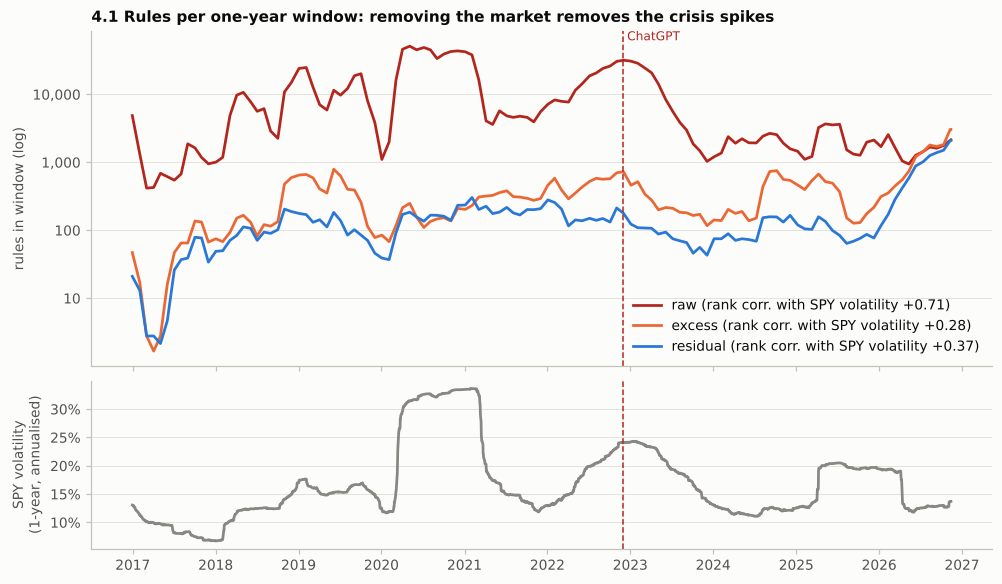

In [9]:
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, layout="constrained",
                              gridspec_kw={"height_ratios": [2, 1]})
for mode in RETURN_MODES:
    ax.plot(rule_counts.index, rule_counts[mode], color=MODE_COLORS[mode],
            label=f"{mode} (rank corr. with SPY volatility {vol_link[mode]:+.2f})")
ax.set_yscale("symlog", linthresh=10)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_ylabel("rules in window (log)")
ax.grid(axis="y")
ax.legend(frameon=False, loc="lower right")
ax.set_title("4.1 Rules per one-year window: removing the market removes the crisis spikes")
mark_chatgpt(ax)
ax2.plot(spy_vol.loc[END_DATES[0]:].index, spy_vol.loc[END_DATES[0]:], color=MUTED)
ax2.set_ylabel("SPY volatility\n(1-year, annualised)")
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax2.grid(axis="y")
year_axis(ax2)
mark_chatgpt(ax2, label=False)
save(fig, "4_1_rules_per_window_by_mode")
plt.show()

**Reading 4.1.** Under `raw` returns the rule count is mostly a picture of market volatility: thousands of rules in 2020 and 2022, when everything fell together. Under `residual` returns the spikes are gone, and the count no longer follows volatility as closely. This is the evidence that raw-return rules partly "rediscover the market", which is the professor's concern in the proposal feedback.

In [10]:
# 4.2 FP-Growth and Apriori must find exactly the same itemsets. Check and time both on the busiest window
# of the main (residual) mode and of the raw mode, where crisis days make baskets much larger.
speed = []
for mode, max_len in [("residual", MAX_LEN), ("raw", MAX_LEN), ("raw", 5)]:
    g = window_summary[window_summary["mode"] == mode]
    busiest = g.loc[g["rules"].idxmax(), "end"]
    end = DAYS.get_loc(busiest)
    basket = items_by_mode[mode].iloc[end - WINDOW + 1:end + 1]
    timings, found = {}, {}
    for algorithm, miner in [("fpgrowth", fpgrowth), ("apriori", apriori)]:
        t0 = time.perf_counter()
        for _ in range(3):
            sets = miner(basket, min_support=MIN_SUPPORT, use_colnames=True, max_len=max_len)
        timings[algorithm] = (time.perf_counter() - t0) / 3
        found[algorithm] = set(sets["itemsets"])
    speed.append({"setting": f"{mode}, up to {max_len} items", "window_end": str(busiest.date()), "items_per_day": round(basket.sum(axis=1).mean(), 1),
                  "itemsets": len(found["fpgrowth"]), "identical": found["fpgrowth"] == found["apriori"],
                  "fpgrowth_ms": round(timings["fpgrowth"] * 1000, 1), "apriori_ms": round(timings["apriori"] * 1000, 1)})
speed = pd.DataFrame(speed).set_index("setting")
KEY["fp_vs_apriori"] = speed.to_dict(orient="index")
speed

,window_end,items_per_day,itemsets,identical,fpgrowth_ms,apriori_ms
setting,,,,,,
"residual, up to 3 items",2026-11-13,10.9,977,True,25.7,8.5
"raw, up to 3 items",2020-05-05,12.2,14018,True,507.7,103.9
"raw, up to 5 items",2020-05-05,12.2,301323,True,3881.1,13100.9


**Reading 4.2.** Both algorithms always return the same itemsets. With our setting of at most 3 items, mlxtend's Apriori is actually *faster*: it only needs three passes, each a fast vectorised count. FP-Growth only overtakes it when longer itemsets are allowed (up to 5 items on the raw crisis window), where Apriori's number of candidates explodes. So at our scale the choice of algorithm does not matter for speed; we keep FP-Growth because its cost grows more slowly if anyone raises `MAX_LEN` or lowers `MIN_SUPPORT`. This is a negative result worth stating rather than repeating the textbook claim.

### 4.3 Are the rules real, or what chance would produce?

With 80 items there are tens of thousands of possible rules, so some will pass the thresholds by luck. Two checks:

- **Shuffle test.** Shuffle each item column on its own. Each stock keeps its number of UP and DOWN days, but any link between stocks is destroyed. Rules found in shuffled baskets are rules chance alone produces. The ratio of chance rules to real rules estimates the share of false discoveries.
- **Fisher exact test with false discovery rate control.** For each rule, the counts of days with the antecedent, with the consequent, and with both form a 2×2 table. The one-sided p-value is the probability of seeing at least that many joint days if the two sides were independent (a hypergeometric tail). The Benjamini–Hochberg procedure then keeps the rules that stay significant when we account for **every rule FP-Growth could have returned** (480,480 possible rules of 2 or 3 items from 40 stocks), not only the ones that passed the thresholds. Counting only the mined rules would understate how much searching was done.

In [11]:
def shuffle_items(basket, rng):
    # Shuffle each item column on its own: item supports stay the same, links between items are destroyed.
    return pd.DataFrame({c: rng.permutation(basket[c].to_numpy()) for c in basket.columns}, index=basket.index)


def rule_p_values(rules, n_days):
    # One-sided Fisher exact test (hypergeometric tail) for "antecedent and consequent co-occur more than by chance".
    n_a = np.rint(rules["antecedent support"] * n_days).astype(int)
    n_c = np.rint(rules["consequent support"] * n_days).astype(int)
    n_ac = np.rint(rules["support"] * n_days).astype(int)
    return hypergeom.sf(n_ac - 1, n_days, n_a, n_c)


def benjamini_hochberg(p_values, q, n_tests=None):
    # True for every p-value that survives the Benjamini-Hochberg false discovery rate procedure at level q.
    # n_tests = how many hypotheses were really looked at (defaults to the number of p-values given).
    p = np.asarray(p_values)
    m = len(p) if n_tests is None else n_tests
    order = np.argsort(p)
    thresholds = q * np.arange(1, len(p) + 1) / m
    passed = p[order] <= thresholds
    keep = np.zeros(len(p), dtype=bool)
    if passed.any():
        keep[order[:np.max(np.nonzero(passed)) + 1]] = True
    return keep


# Every rule of 2 or 3 items that could exist (two items from the same stock never co-occur, so they are excluded):
# pairs: C(40,2) stock pairs x 4 direction combinations x 2 orientations;
# triples: C(40,3) x 8 direction combinations x 6 ways to split into antecedent -> consequent.
from math import comb
N_POSSIBLE_RULES = comb(len(TICKERS), 2) * 4 * 2 + comb(len(TICKERS), 3) * 8 * 6
print(f"Possible rules with at most {MAX_LEN} items: {N_POSSIBLE_RULES:,}")

rng = np.random.default_rng(SEED)
chance = []
for end_date, rules in rules_by_window.items():
    end = DAYS.get_loc(end_date)
    basket = items.iloc[end - WINDOW + 1:end + 1]
    shuffled_counts = [len(mine_rules(shuffle_items(basket, rng))) for _ in range(N_SHUFFLES)]
    if len(rules):
        rules["p_value"] = rule_p_values(rules, WINDOW)
        rules["significant"] = benjamini_hochberg(rules["p_value"], FDR_Q, n_tests=N_POSSIBLE_RULES)
    chance.append({"end": end_date, "real": len(rules), "shuffled": np.mean(shuffled_counts),
                   "significant": int(rules["significant"].sum()) if len(rules) else 0})
chance = pd.DataFrame(chance).set_index("end")
chance["chance_ratio"] = chance["shuffled"] / chance["real"].replace(0, np.nan)
chance.to_csv(OUT_DIR / "chance_test.csv")
KEY["chance"] = {"n_possible_rules": N_POSSIBLE_RULES,
    "real_rules_total": int(chance["real"].sum()), "shuffled_rules_total": round(float(chance["shuffled"].sum()), 1),
    "chance_ratio_overall": round(float(chance["shuffled"].sum() / chance["real"].sum()), 3),
    "significant_share": round(float(chance["significant"].sum() / chance["real"].sum()), 3),
}
print(KEY["chance"])

Possible rules with at most 3 items: 480,480


{'n_possible_rules': 480480, 'real_rules_total': 24585, 'shuffled_rules_total': 67.0, 'chance_ratio_overall': 0.003, 'significant_share': 0.823}


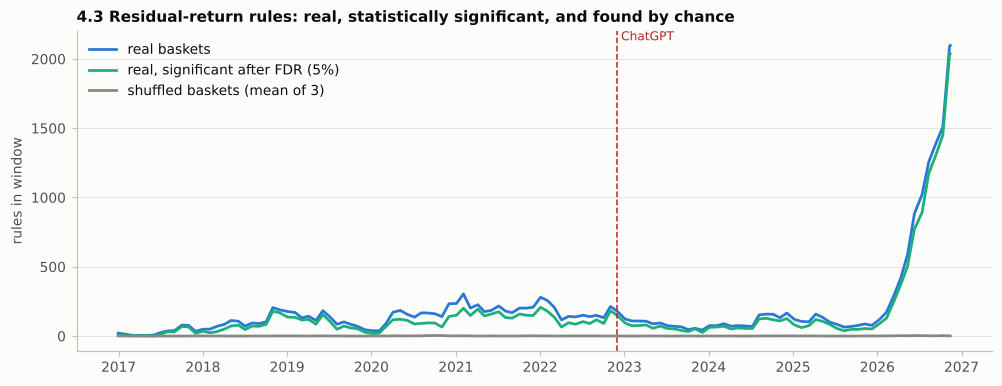

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.4), layout="constrained")
ax.plot(chance.index, chance["real"], color=MODE_COLORS["residual"], label="real baskets")
ax.plot(chance.index, chance["significant"], color="#1baf7a", label=f"real, significant after FDR ({FDR_Q:.0%})")
ax.plot(chance.index, chance["shuffled"], color=MUTED, label=f"shuffled baskets (mean of {N_SHUFFLES})")
ax.set_ylabel("rules in window")
ax.grid(axis="y")
ax.legend(frameon=False, loc="upper left")
year_axis(ax)
ax.set_title("4.3 Residual-return rules: real, statistically significant, and found by chance")
mark_chatgpt(ax)
save(fig, "4_3_chance_test")
plt.show()

## 5. Did ChatGPT change how these stocks move together?

The proposal compared "before" with "after". That cannot separate ChatGPT from everything else that happened in late 2022. Here the question is tested in three steps.

**5.1 Co-movement between and within groups over time.** For each window we compute the *pair lift* of every pair of stocks: how much more often than chance they made a major move in the same direction on the same day (1 = chance, 2 = twice as often). Averaging inside and between groups gives one line per group pair.

**5.2 Placebo test.** For every month from 2017 to 2025 we pretend the break happened there and measure how much the co-movement structure changed between the year before and the year after. If ChatGPT really changed things, its change should be among the largest. With overlapping years, neighbouring dates are not independent, so the honest reading is "how unusual", not an exact p-value.

**5.3 Control group.** The change is measured for tech pairs *minus* the change for non-tech pairs, so a change that hits every stock (rates, recessions) cancels out.

Stated before running (so the result can prove us wrong): *if ChatGPT re-wired tech co-movement, the December 2022 break should rank in the top 10% of placebo dates on the tech-minus-control measures.* A lower rank means our data cannot attribute a change to ChatGPT.

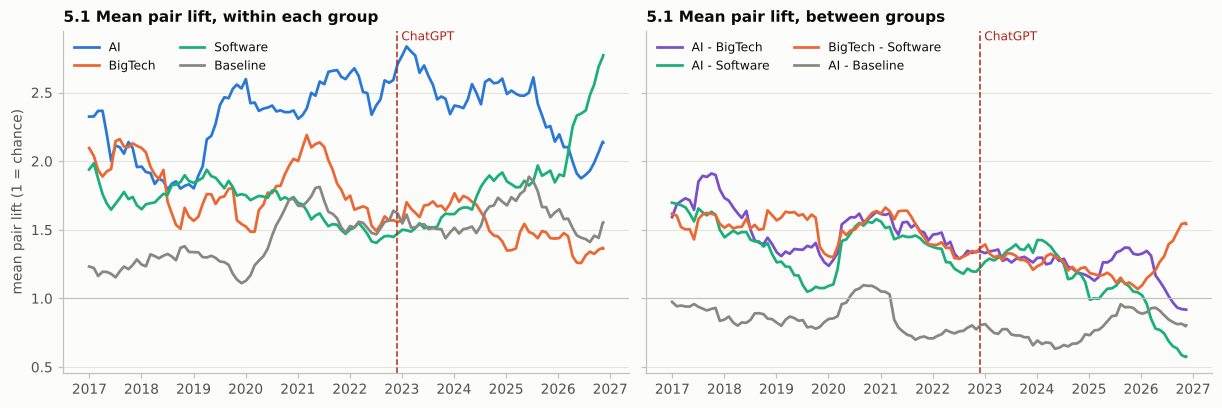

,year to Nov 2022,year to Nov 2023,year to Nov 2026
AI-AI,2.71,2.34,2.13
AI-BigTech,1.34,1.26,0.92
AI-Software,1.23,1.33,0.58
AI-Baseline,0.81,0.66,0.80
BigTech-BigTech,1.56,1.69,1.36
BigTech-Software,1.37,1.21,1.54
BigTech-Baseline,0.77,0.77,0.98
Software-Software,1.47,1.61,2.77
Software-Baseline,0.99,0.91,1.11
Baseline-Baseline,1.62,1.48,1.55


In [13]:
def pair_lift_matrix(basket, tickers=TICKERS):
    # For every pair of stocks: lift of "both made a major move in the same direction on the same day".
    up = basket[[f"{t}_UP" for t in tickers]].to_numpy(dtype=float)
    down = basket[[f"{t}_DOWN" for t in tickers]].to_numpy(dtype=float)
    together = (up.T @ up + down.T @ down) / len(basket)          # share of days both moved the same way
    by_chance = np.outer(up.mean(0), up.mean(0)) + np.outer(down.mean(0), down.mean(0))
    lift = np.divide(together, by_chance, out=np.full_like(together, np.nan), where=by_chance > 0)
    np.fill_diagonal(lift, np.nan)
    return lift


GROUP_IDX = {g: [TICKERS.index(t) for t in members] for g, members in GROUPS.items()}
SHORT = {"AI enablers": "AI", "Big Tech": "BigTech", "Traditional software": "Software", "Non-tech baseline": "Baseline"}
BLOCKS = [(g, h) for i, g in enumerate(GROUPS) for h in list(GROUPS)[i:]]


def block_means(lift):
    # Mean pair lift inside each group and between each pair of groups.
    return {f"{SHORT[g]}-{SHORT[h]}": np.nanmean(lift[np.ix_(GROUP_IDX[g], GROUP_IDX[h])]) for g, h in BLOCKS}


lift_by_window = {d: pair_lift_matrix(items.iloc[DAYS.get_loc(d) - WINDOW + 1:DAYS.get_loc(d) + 1]) for d in END_DATES}
blocks_over_time = pd.DataFrame({d: block_means(L) for d, L in lift_by_window.items()}).T
blocks_over_time.to_csv(OUT_DIR / "group_block_lift_over_time.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, layout="constrained")
within = ["AI-AI", "BigTech-BigTech", "Software-Software", "Baseline-Baseline"]
between = ["AI-BigTech", "AI-Software", "BigTech-Software", "AI-Baseline"]
colors = list(GROUP_COLORS.values())
for col, c in zip(within, colors):
    axes[0].plot(blocks_over_time.index, blocks_over_time[col], color=c, label=col.split("-")[0])
for col, c in zip(between, ["#7a4fc9", "#1baf7a", "#eb6834", MUTED]):
    axes[1].plot(blocks_over_time.index, blocks_over_time[col], color=c, label=col.replace("-", " - "))
for ax, title in zip(axes, ["Within each group", "Between groups"]):
    ax.axhline(1, color=AXIS, lw=0.8)
    ax.grid(axis="y")
    ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=2)
    year_axis(ax)
    ax.set_title(f"5.1 Mean pair lift, {title.lower()}")
    mark_chatgpt(ax)
axes[0].set_ylabel("mean pair lift (1 = chance)")
save(fig, "5_1_group_lift_over_time")
plt.show()


def window_at(date):
    return blocks_over_time.index[blocks_over_time.index.get_indexer([pd.Timestamp(date)], method="nearest")[0]]


snapshot = blocks_over_time.loc[[window_at("2022-11-30"), window_at("2023-11-30"), END_DATES[-1]]].T
snapshot.columns = ["year to Nov 2022", "year to Nov 2023", "year to Nov 2026"]
KEY["block_lift_snapshot"] = snapshot.round(2).to_dict()
snapshot.round(2)

In [14]:
def break_statistics(its, pos, span=BREAK_SPAN, **mine_kwargs):
    # Compare the `span` baskets before day `pos` with the `span` baskets from `pos` on.
    pre, post = its.iloc[pos - span:pos], its.iloc[pos:pos + span]
    r_pre, r_post = mine_rules(pre, **mine_kwargs), mine_rules(post, **mine_kwargs)
    s_pre = set(r_pre["rule"]) if len(r_pre) else set()
    s_post = set(r_post["rule"]) if len(r_post) else set()
    union = s_pre | s_post
    l_pre, l_post = pair_lift_matrix(pre), pair_lift_matrix(post)
    b_pre, b_post = block_means(l_pre), block_means(l_post)
    # Change in log2 pair lift (so doubling and halving count the same), clipped against tiny counts.
    change = np.abs(np.log2(np.clip(l_post, 0.25, 8)) - np.log2(np.clip(l_pre, 0.25, 8)))
    tech = [i for g in ["AI enablers", "Big Tech", "Traditional software"] for i in GROUP_IDX[g]]
    base = GROUP_IDX["Non-tech baseline"]
    return {
        "rule_turnover": 1 - len(s_pre & s_post) / len(union) if union else np.nan,
        "tech_change_minus_control": np.nanmean(change[np.ix_(tech, tech)]) - np.nanmean(change[np.ix_(base, base)]),
        "ai_within_did": (b_post["AI-AI"] - b_pre["AI-AI"]) - (b_post["Baseline-Baseline"] - b_pre["Baseline-Baseline"]),
        "ai_software_change": b_post["AI-Software"] - b_pre["AI-Software"],
    }


def candidate_break_positions(its, span=BREAK_SPAN):
    # First trading day of every month that has `span` baskets on both sides.
    first_of_month = its.index.to_series().groupby(its.index.to_period("M")).first()
    pos = [its.index.get_loc(d) for d in first_of_month]
    return [p for p in pos if p - span >= 0 and p + span <= len(its)]


def placebo_table(its, span=BREAK_SPAN, **mine_kwargs):
    rows = {its.index[p]: break_statistics(its, p, span, **mine_kwargs) for p in candidate_break_positions(its, span)}
    return pd.DataFrame(rows).T


def percentile_of(table, date, col, two_sided=False):
    # Share of candidate dates whose value is at or below ChatGPT's (a high percentile = an unusually large change).
    values = table[col].abs() if two_sided else table[col]
    return float((values <= values.loc[pd.Timestamp(date)]).mean())


placebo = placebo_table(items)
placebo.to_csv(OUT_DIR / "placebo_break_test.csv")
CG = pd.Timestamp(CHATGPT_DATE)
assert CG in placebo.index, "the ChatGPT date must be one of the candidate dates"
METRICS = {
    "rule_turnover": ("Rule turnover (Jaccard distance)", False),
    "tech_change_minus_control": ("Tech pair change minus control change", False),
    "ai_within_did": ("AI-AI lift change minus baseline change", True),
    "ai_software_change": ("AI-Software lift change", True),
}
pct = {m: percentile_of(placebo, CHATGPT_DATE, m, two) for m, (_, two) in METRICS.items()}
KEY["placebo"] = {"n_candidate_dates": len(placebo), "first": str(placebo.index[0].date()), "last": str(placebo.index[-1].date()),
                  "chatgpt_values": placebo.loc[CG].round(3).to_dict(), "chatgpt_percentile": {k: round(v, 2) for k, v in pct.items()},
                  "top_dates_tech_change": [str(d.date()) for d in placebo["tech_change_minus_control"].nlargest(5).index],
                  "top_dates_turnover": [str(d.date()) for d in placebo["rule_turnover"].nlargest(5).index]}
# Nvidia's guidance (25 May 2023) is the date the market reacted most to AI (Section 8); check it as an alternative break.
NVDA_BREAK = pd.Timestamp("2023-06-01")
KEY["placebo"]["nvidia_guidance_percentile"] = {k: round(percentile_of(placebo, NVDA_BREAK, k, two), 2) for k, (_, two) in METRICS.items()}
print(json.dumps(KEY["placebo"], indent=1))

{
 "n_candidate_dates": 107,
 "first": "2017-01-03",
 "last": "2025-11-03",
 "chatgpt_values": {
  "rule_turnover": 0.887,
  "tech_change_minus_control": 0.012,
  "ai_within_did": -0.207,
  "ai_software_change": 0.103
 },
 "chatgpt_percentile": {
  "rule_turnover": 0.62,
  "tech_change_minus_control": 0.29,
  "ai_within_did": 0.36,
  "ai_software_change": 0.21
 },
 "top_dates_tech_change": [
  "2025-11-03",
  "2025-10-01",
  "2025-09-02",
  "2025-08-01",
  "2024-08-01"
 ],
 "top_dates_turnover": [
  "2017-05-01",
  "2017-04-03",
  "2025-11-03",
  "2025-10-01",
  "2025-09-02"
 ],
 "nvidia_guidance_percentile": {
  "rule_turnover": 0.04,
  "tech_change_minus_control": 0.3,
  "ai_within_did": 0.32,
  "ai_software_change": 0.05
 }
}


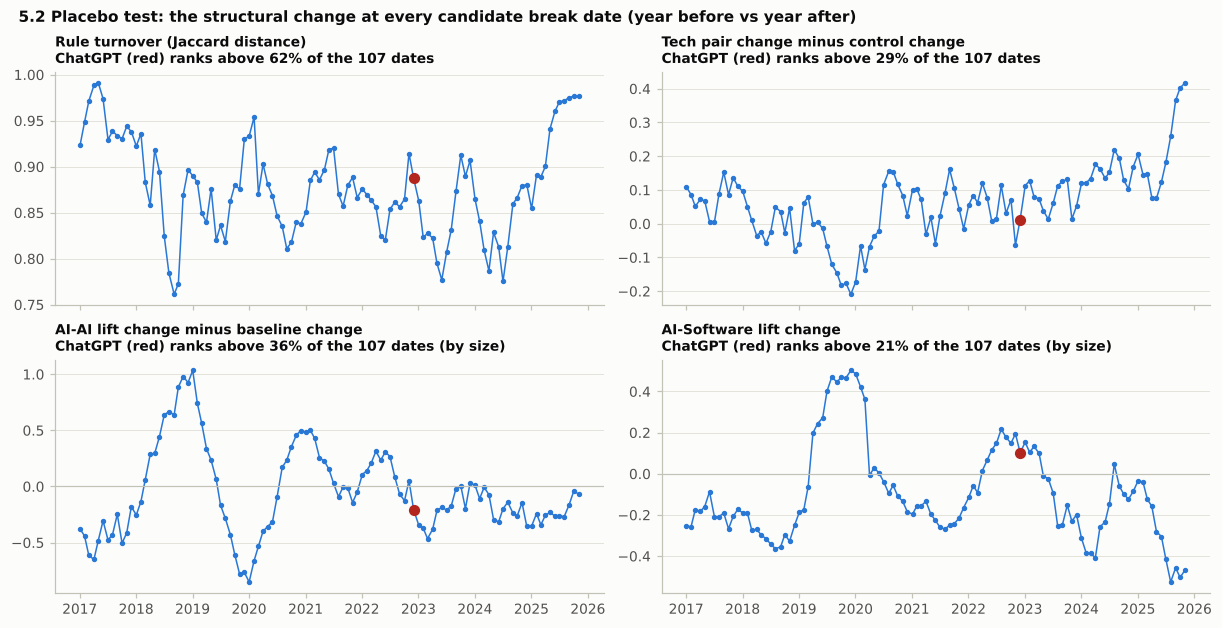

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), sharex=True, layout="constrained")
for ax, (m, (title, two)) in zip(axes.flat, METRICS.items()):
    ax.plot(placebo.index, placebo[m], color=MODE_COLORS["residual"], marker="o", markersize=2.5, lw=1)
    ax.scatter([CG], [placebo.loc[CG, m]], color=HIGHLIGHT, s=40, zorder=5)
    if two:
        ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_title(f"{title}\nChatGPT (red) ranks above {pct[m]:.0%} of the {len(placebo)} dates" + (" (by size)" if two else ""), fontsize=9)
    ax.grid(axis="y")
    year_axis(ax)
fig.suptitle("5.2 Placebo test: the structural change at every candidate break date (year before vs year after)",
             x=0.01, ha="left", fontweight="bold", fontsize=10)
save(fig, "5_2_placebo_break_test")
plt.show()

### 5.4 Does the answer survive a change of settings?

The same ChatGPT percentiles under other return definitions, move thresholds, support levels and window lengths. A result that only appears in one setting is fragile.

In [16]:
def items_for(mode, z_k):
    its, _ = find_major_moves(returns_by_mode[mode], z_k, VOL_WINDOW)
    return its.loc[STUDY_START:]


settings = [
    ("main: residual, z=1.0, sup=0.04, 1y", dict(mode="residual", z_k=1.0, span=252, min_support=0.04)),
    ("raw returns", dict(mode="raw", z_k=1.0, span=252, min_support=0.04)),
    ("excess returns", dict(mode="excess", z_k=1.0, span=252, min_support=0.04)),
    ("z = 1.5 (rarer moves)", dict(mode="residual", z_k=1.5, span=252, min_support=0.02)),
    ("support 0.03", dict(mode="residual", z_k=1.0, span=252, min_support=0.03)),
    ("support 0.05", dict(mode="residual", z_k=1.0, span=252, min_support=0.05)),
    ("half-year windows", dict(mode="residual", z_k=1.0, span=126, min_support=0.04)),
]
robust = {}
for name, s in settings:
    its = items_for(s["mode"], s["z_k"])
    table = placebo_table(its, span=s["span"], min_support=s["min_support"])
    robust[name] = {METRICS[m][0]: percentile_of(table, CHATGPT_DATE, m, METRICS[m][1]) for m in METRICS}
robust = pd.DataFrame(robust).T
robust.to_csv(OUT_DIR / "placebo_robustness.csv")
KEY["placebo_robustness"] = robust.round(2).to_dict(orient="index")
(robust * 100).round(0)

,Rule turnover (Jaccard distance),Tech pair change minus control change,AI-AI lift change minus baseline change,AI-Software lift change
"main: residual, z=1.0, sup=0.04, 1y",62.0,29.0,36.0,21.0
raw returns,94.0,91.0,2.0,42.0
excess returns,81.0,30.0,28.0,19.0
z = 1.5 (rarer moves),10.0,95.0,35.0,47.0
support 0.03,80.0,29.0,36.0,21.0
support 0.05,55.0,29.0,36.0,21.0
half-year windows,43.0,29.0,86.0,14.0


## 6. Which stocks does the market treat as "AI stocks"?

The four groups were chosen by us. Here the data decides. For every stock and every window we compute its **AI affinity**: the mean pair lift between that stock and the ten AI enablers (excluding itself). An affinity of 2 means the stock makes same-direction major moves with chip stocks twice as often as chance, *after* the market has been removed.

Finance research calls this *category-based co-movement* (Barberis, Shleifer and Wurgler, 2005): when investors put stocks into one category and buy or sell the category as a whole, the stocks move together even if their businesses are unrelated. If "AI" became such a category after ChatGPT, stocks should join or leave the AI cluster in ways their sector labels do not predict.

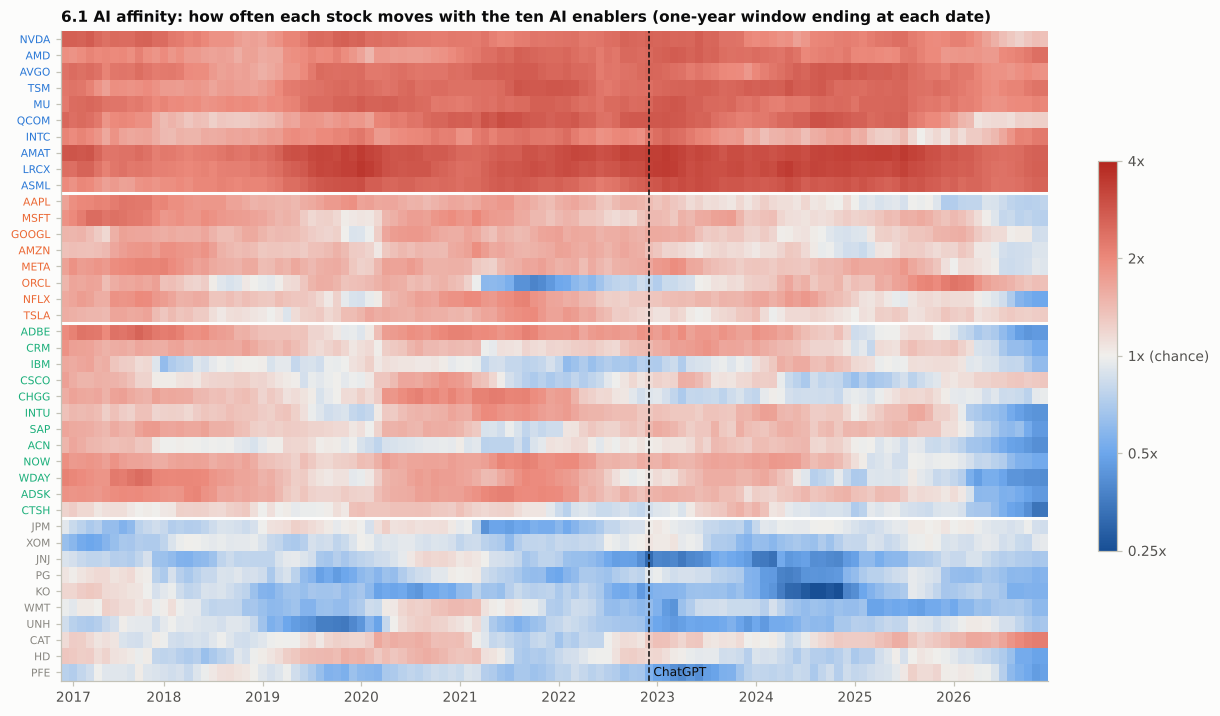

In [17]:
ai_idx = GROUP_IDX["AI enablers"]
affinity = pd.DataFrame({d: np.nanmean(L[:, ai_idx], axis=1) for d, L in lift_by_window.items()}, index=TICKERS).T
affinity.to_csv(OUT_DIR / "ai_affinity_over_time.csv")

fig, ax = plt.subplots(figsize=(11, 6.4), layout="constrained")
logged = np.log2(affinity.T.clip(0.25, 4).to_numpy())
image = ax.imshow(logged, aspect="auto", cmap=LIFT_CMAP, vmin=-2, vmax=2, interpolation="nearest")
ax.set_yticks(range(len(TICKERS)), TICKERS, fontsize=7)
for tick, t in zip(ax.get_yticklabels(), TICKERS):
    tick.set_color(GROUP_COLORS[GROUP_OF[t]])
edges = np.cumsum([len(m) for m in GROUPS.values()])[:-1] - 0.5
for e in edges:
    ax.axhline(e, color=SURFACE, lw=2)
year_ticks = [i for i, d in enumerate(affinity.index) if i > 0 and d.year != affinity.index[i - 1].year]
ax.set_xticks(year_ticks, [affinity.index[i].year for i in year_ticks])
cg_col = affinity.index.get_indexer([CG], method="nearest")[0]
ax.axvline(cg_col, color=INK, lw=1, ls="--")
ax.text(cg_col + 0.5, len(TICKERS) - 0.6, "ChatGPT", ha="left", va="bottom", fontsize=8, color=INK)
bar = fig.colorbar(image, ax=ax, shrink=0.6, ticks=[-2, -1, 0, 1, 2])
bar.ax.set_yticklabels(["0.25x", "0.5x", "1x (chance)", "2x", "4x"])
ax.set_title("6.1 AI affinity: how often each stock moves with the ten AI enablers (one-year window ending at each date)")
save(fig, "6_1_ai_affinity_heatmap")
plt.show()

### 6.2 Which changes are bigger than noise?

Compare each stock's AI affinity in the two years before ChatGPT with the most recent two years. A **block bootstrap** resamples 10-day blocks of baskets (keeping short bursts of related days together) 500 times per period, which gives a 95% interval for the change. With 40 stocks tested, about two would cross a 95% line by luck, so the Benjamini–Hochberg procedure is applied again to the bootstrap p-values.

In [18]:
def block_bootstrap(basket, rng, block=10):
    # Resample whole blocks of consecutive days, with replacement, to the original length.
    n = len(basket)
    starts = rng.integers(0, n - block + 1, size=int(np.ceil(n / block)))
    rows = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
    return basket.iloc[rows]


def ai_affinity(basket):
    return np.nanmean(pair_lift_matrix(basket)[:, ai_idx], axis=1)


cg_pos = DAYS.get_loc(CG)
PERIODS = {"pre (Dec 2020 - Nov 2022)": items.iloc[cg_pos - 504:cg_pos],
           "post (Dec 2022 - Nov 2024)": items.iloc[cg_pos:cg_pos + 504],
           "latest (Nov 2024 - Nov 2026)": items.iloc[-504:]}
N_BOOT = 500
rng = np.random.default_rng(SEED)
boot = {name: np.array([ai_affinity(block_bootstrap(b, rng)) for _ in range(N_BOOT)]) for name, b in PERIODS.items()}
point = {name: ai_affinity(b) for name, b in PERIODS.items()}
names = list(PERIODS)
diff_boot = boot[names[2]] - boot[names[0]]
change = pd.DataFrame({
    "group": [GROUP_OF[t] for t in TICKERS],
    "pre": point[names[0]], "post": point[names[1]], "latest": point[names[2]],
    "change": point[names[2]] - point[names[0]],
    "ci_low": np.percentile(diff_boot, 2.5, axis=0), "ci_high": np.percentile(diff_boot, 97.5, axis=0),
}, index=TICKERS)
# Two-sided bootstrap p-value: how often the resampled change falls on the other side of zero.
change["p_boot"] = np.minimum(1, 2 * np.minimum((diff_boot <= 0).mean(0), (diff_boot >= 0).mean(0)))
change["significant"] = benjamini_hochberg(change["p_boot"], FDR_Q)
change = change.sort_values("change")
change.to_csv(OUT_DIR / "ai_affinity_change.csv")
KEY["affinity_change"] = {
    "risers": change[change["significant"] & (change["change"] > 0)].index.tolist()[::-1],
    "fallers": change[change["significant"] & (change["change"] < 0)].index.tolist(),
    "table": change[["group", "pre", "post", "latest", "change", "ci_low", "ci_high", "significant"]].round(2).to_dict(orient="index"),
}
change.round(2)

,group,pre,post,latest,change,ci_low,ci_high,p_boot,significant
ADBE,Traditional software,1.83,1.48,0.66,-1.17,-1.52,-0.76,0.00,True
QCOM,AI enablers,2.71,2.52,1.62,-1.09,-1.61,-0.64,0.00,True
ADSK,Traditional software,1.72,1.33,0.72,-1.00,-1.39,-0.58,0.00,True
NOW,Traditional software,1.69,1.50,0.69,-1.00,-1.36,-0.61,0.00,True
WDAY,Traditional software,1.44,1.14,0.57,-0.87,-1.22,-0.47,0.00,True
INTU,Traditional software,1.54,1.34,0.70,-0.84,-1.18,-0.44,0.00,True
NVDA,AI enablers,2.44,2.13,1.64,-0.80,-1.18,-0.34,0.00,True
NFLX,Big Tech,1.50,1.43,0.78,-0.72,-1.12,-0.30,0.00,True
AAPL,Big Tech,1.41,1.13,0.78,-0.63,-1.04,-0.36,0.00,True
META,Big Tech,1.63,1.45,1.07,-0.56,-1.00,-0.12,0.02,True


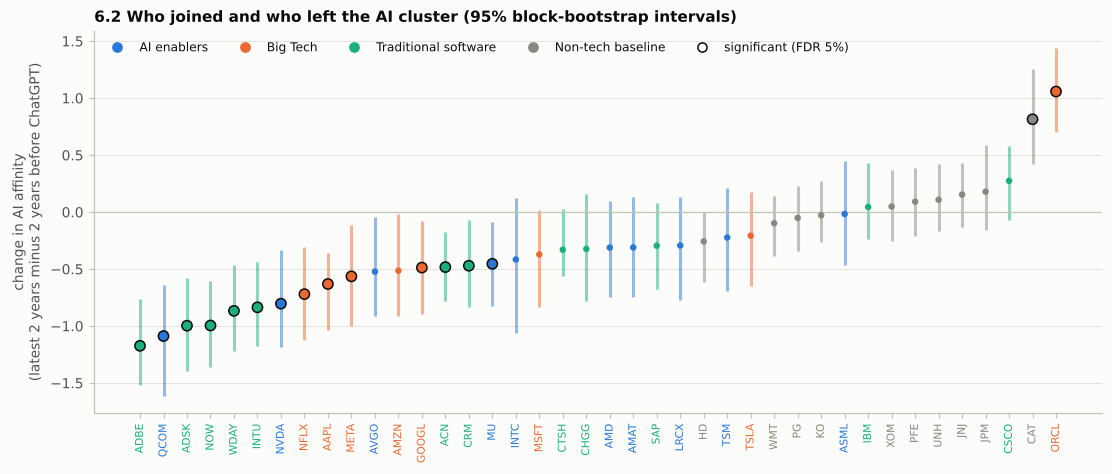

In [19]:
fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
x = np.arange(len(change))
colors_ = [GROUP_COLORS[g] for g in change["group"]]
ax.vlines(x, change["ci_low"], change["ci_high"], color=colors_, lw=2, alpha=0.5)
ax.scatter(x, change["change"], c=colors_, s=[45 if s else 18 for s in change["significant"]], zorder=3,
           edgecolor=[INK if s else "none" for s in change["significant"]])
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xticks(x, change.index, rotation=90, fontsize=7)
for tick, t in zip(ax.get_xticklabels(), change.index):
    tick.set_color(GROUP_COLORS[GROUP_OF[t]])
ax.set_ylabel("change in AI affinity\n(latest 2 years minus 2 years before ChatGPT)")
ax.grid(axis="y")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=g) for g, c in GROUP_COLORS.items()]
handles.append(plt.Line2D([], [], marker="o", ls="", color=SURFACE, markeredgecolor=INK, label="significant (FDR 5%)"))
ax.legend(handles=handles, frameon=False, fontsize=8, ncol=5, loc="upper left")
ax.set_title("6.2 Who joined and who left the AI cluster (95% block-bootstrap intervals)")
save(fig, "6_2_ai_affinity_change")
plt.show()

### 6.3 Clustering cross-check: do the data's own groups match ours?

Each window's 40 stocks are clustered into 4 groups using the **Jaccard distance** between their move records (UP days followed by DOWN days; two stocks are close when they tend to move on the same days in the same direction). Two methods are compared:

- **Hierarchical clustering, average linkage**: repeatedly merges the two closest clusters; average linkage uses the mean distance between members, which is less sensitive to one odd pair than complete linkage.
- **Spectral clustering**: treats the similarities as a graph and cuts it where few strong links cross. It can find groups that are not compact "balls".

The Adjusted Rand Index (ARI) measures agreement with our four groups (1 = identical, 0 = no better than random labels).

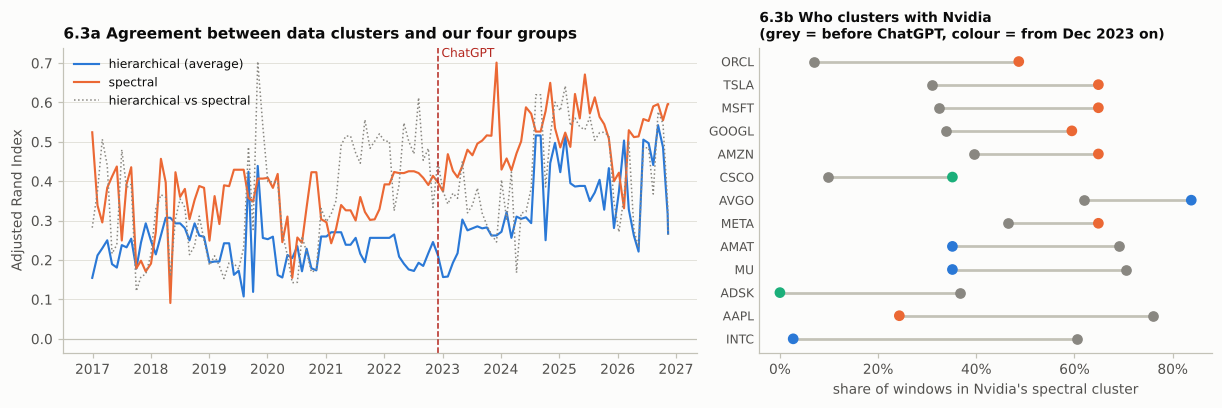

,before ChatGPT,after ChatGPT,change
ORCL,0.07,0.49,0.42
TSLA,0.31,0.65,0.34
MSFT,0.32,0.65,0.32
GOOGL,0.34,0.59,0.26
AMZN,0.39,0.65,0.25
CSCO,0.10,0.35,0.25
AVGO,0.62,0.84,0.22
META,0.46,0.65,0.18
SAP,0.01,0.11,0.09
JPM,0.01,0.08,0.07


In [20]:
def move_records(basket, tickers=TICKERS):
    # One row per stock: its UP days followed by its DOWN days, as True/False.
    return np.array([np.concatenate([basket[f"{t}_UP"].to_numpy(), basket[f"{t}_DOWN"].to_numpy()]) for t in tickers])


def cluster_window(basket, k=4, seed=SEED):
    dist = np.nan_to_num(pdist(move_records(basket), metric="jaccard"), nan=1.0)
    hier = fcluster(linkage(dist, method="average"), t=k, criterion="maxclust")
    similarity = 1 - squareform(dist)
    spectral = SpectralClustering(n_clusters=k, affinity="precomputed", random_state=seed,
                                  assign_labels="cluster_qr").fit_predict(similarity)
    return hier, spectral


true_labels = [GROUP_OF[t] for t in TICKERS]
clusters = {}
for d in END_DATES:
    end = DAYS.get_loc(d)
    clusters[d] = cluster_window(items.iloc[end - WINDOW + 1:end + 1])
ari = pd.DataFrame({d: {"hierarchical (average)": adjusted_rand_score(true_labels, h),
                        "spectral": adjusted_rand_score(true_labels, s),
                        "hierarchical vs spectral": adjusted_rand_score(h, s)}
                    for d, (h, s) in clusters.items()}).T
# Which stocks share Nvidia's cluster? Share of windows, before vs after ChatGPT (spectral clustering).
nvda = TICKERS.index("NVDA")
same_as_nvda = pd.DataFrame({d: (s == s[nvda]) for d, (h, s) in clusters.items()}, index=TICKERS).T
with_nvda = pd.DataFrame({
    "before ChatGPT": same_as_nvda[same_as_nvda.index < CG].mean(),
    "after ChatGPT": same_as_nvda[same_as_nvda.index >= CG + pd.Timedelta(days=365)].mean(),
})
with_nvda["change"] = with_nvda["after ChatGPT"] - with_nvda["before ChatGPT"]
with_nvda = with_nvda.drop("NVDA").sort_values("change", ascending=False)
ari.to_csv(OUT_DIR / "cluster_ari_over_time.csv")
with_nvda.to_csv(OUT_DIR / "share_of_windows_in_nvidia_cluster.csv")
KEY["clustering"] = {
    "ari_mean_before": ari[ari.index < CG].mean().round(2).to_dict(),
    "ari_mean_after": ari[ari.index >= CG + pd.Timedelta(days=365)].mean().round(2).to_dict(),
    "joined_nvda_cluster": with_nvda.head(6).round(2).to_dict(orient="index"),
    "left_nvda_cluster": with_nvda.tail(4).round(2).to_dict(orient="index"),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained", gridspec_kw={"width_ratios": [1.4, 1]})
for col, c in zip(ari.columns, ["#2a78d6", "#eb6834", MUTED]):
    axes[0].plot(ari.index, ari[col], color=c, label=col, lw=1.4 if col != "hierarchical vs spectral" else 1, ls="-" if col != "hierarchical vs spectral" else ":")
axes[0].axhline(0, color=AXIS, lw=0.8)
axes[0].set_ylabel("Adjusted Rand Index")
axes[0].grid(axis="y")
axes[0].legend(frameon=False, fontsize=8)
year_axis(axes[0])
axes[0].set_title("6.3a Agreement between data clusters and our four groups")
mark_chatgpt(axes[0])
top = pd.concat([with_nvda.head(8), with_nvda.tail(5)])
y = np.arange(len(top))[::-1]
axes[1].hlines(y, top["before ChatGPT"], top["after ChatGPT"], color=AXIS)
axes[1].scatter(top["before ChatGPT"], y, color=MUTED, zorder=3)
axes[1].scatter(top["after ChatGPT"], y, color=[GROUP_COLORS[GROUP_OF[t]] for t in top.index], zorder=3)
for t, yy in zip(top.index, y):
    axes[1].tick_params(axis="y", length=0)
axes[1].set_yticks(y, top.index, fontsize=8)
axes[1].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[1].set_xlabel("share of windows in Nvidia's spectral cluster")
axes[1].set_title("6.3b Who clusters with Nvidia\n(grey = before ChatGPT, colour = from Dec 2023 on)", fontsize=9)
save(fig, "6_3_clusters")
plt.show()
with_nvda.round(2).head(10)

## 7. Which co-movement rules last? (prediction in service of the patterns)

A portfolio manager who uses a mined rule, for example "when AMAT jumps, LRCX jumps too", to judge diversification needs to know whether it will still hold next month. Sections 4–6 show the rule sets change. Here we ask **what makes a rule durable**.

**Target.** A rule mined from the window ending on day *t* *survives* if it is mined again, with the same thresholds, from the next 126 baskets (days *t*+1 to *t*+126). Those future days never overlap the window the rule came from.

**Features (all known on day *t*).**

| Feature | Meaning |
|---|---|
| `support`, `confidence`, `lift`, `leverage`, `conviction` | the rule's strength in its window |
| `neg_log10_p` | Fisher test strength (Section 4.3) |
| `n_items`, `n_groups`, `has_baseline`, `has_ai`, `dir_*` | what kind of stocks and moves the rule links (`n_groups` = 1 means all its stocks are in one of our four groups) |
| `age` | in how many consecutive earlier windows (21 days apart) the same rule was already found |
| `seen_last_12` | in how many of the last 12 windows it was found |
| `recent_share` | share of the rule's joint days that fell in the window's last quarter (0.25 if spread evenly) |
| `burstiness` | largest share of its joint days inside any 21-day block: high = the rule comes from one episode |
| `shock_share` | share of its joint days that were "shock days" (basket size in the top 5% of the previous year) |
| `spy_vol`, `spy_vol_recent`, `items_per_day` | the market regime of the window |

**Split.** Train on windows whose 126 future days end before ChatGPT; test on windows that end after ChatGPT. Nothing from the test period is used in training, and the test asks whether pre-ChatGPT "laws of durability" still hold after it.

**Models and baselines.** Logistic regression (readable coefficients), random forest and histogram gradient boosting, against one-feature baselines that rank rules by lift, support, confidence or age.

In [21]:
def joint_days(basket_np, col_of, rule_items):
    # True on the days when every item of the rule is in the basket.
    return basket_np[:, [col_of[i] for i in rule_items]].all(axis=1)


def future_holds(future_np, col_of, antecedents, consequents):
    # Is the rule mined again from the future baskets with the same thresholds?
    a = future_np[:, [col_of[i] for i in antecedents]].all(axis=1)
    c = future_np[:, [col_of[i] for i in consequents]].all(axis=1)
    sup_a, sup_c, sup_ac = a.mean(), c.mean(), (a & c).mean()
    conf = sup_ac / sup_a if sup_a > 0 else 0.0
    lift = conf / sup_c if sup_c > 0 else 0.0
    return (sup_ac >= MIN_SUPPORT) and (conf >= MIN_CONFIDENCE) and (lift >= MIN_LIFT)


basket_size = items.sum(axis=1)
shock_cut = basket_size.rolling(WINDOW).quantile(0.95).shift(1)        # past-only threshold
shock_day = (basket_size > shock_cut).to_numpy()
items_np = items.to_numpy(dtype=bool)
COL_OF = {c: i for i, c in enumerate(items.columns)}
spy_recent = market_returns.loc[STUDY_START:].rolling(STEP).std() * np.sqrt(252)

rule_sets = {d: set(r["rule"]) if len(r) else set() for d, r in rules_by_window.items()}
ordered_dates = list(rules_by_window)
records = []
for k, d in enumerate(ordered_dates):
    rules = rules_by_window[d]
    if rules.empty:
        continue
    end = DAYS.get_loc(d)
    window_np = items_np[end - WINDOW + 1:end + 1]
    window_shock = shock_day[end - WINDOW + 1:end + 1]
    has_future = end + FUTURE_DAYS < len(items)
    future_np = items_np[end + 1:end + 1 + FUTURE_DAYS] if has_future else None
    for _, r in rules.iterrows():
        age = 0
        while k - age - 1 >= 0 and r["rule"] in rule_sets[ordered_dates[k - age - 1]]:
            age += 1
        seen = sum(r["rule"] in rule_sets[ordered_dates[j]] for j in range(max(0, k - 12), k))
        days_on = joint_days(window_np, COL_OF, r["antecedents"] | r["consequents"])
        n_on = days_on.sum()
        blocks = days_on[: (WINDOW // STEP) * STEP].reshape(-1, STEP).sum(axis=1)
        records.append({
            "window_end": d, "rule": r["rule"],
            "support": r["support"], "confidence": r["confidence"], "lift": r["lift"],
            "leverage": r["leverage"], "conviction": min(r["conviction"], 10),
            "neg_log10_p": -np.log10(max(r["p_value"], 1e-300)),
            "n_items": r["n_items"], "cross_group": int(r["cross_group"]), "n_groups": r["n_groups"],
            "has_baseline": int(r["has_baseline"]), "has_ai": int(r["has_ai"]),
            "dir_up": int(r["direction"] == "UP"), "dir_down": int(r["direction"] == "DOWN"),
            "age": age, "seen_last_12": seen,
            "recent_share": days_on[-63:].sum() / n_on, "burstiness": blocks.max() / n_on,
            "shock_share": (days_on & window_shock).sum() / n_on,
            "spy_vol": spy_vol.loc[d], "spy_vol_recent": spy_recent.loc[d], "items_per_day": basket_size.iloc[end - WINDOW + 1:end + 1].mean(),
            "survived": (int(future_holds(future_np, COL_OF, r["antecedents"], r["consequents"])) if has_future else np.nan),
        })
survival = pd.DataFrame(records)
FEATURES = ["support", "confidence", "lift", "leverage", "conviction", "neg_log10_p", "n_items",
            "n_groups", "has_baseline", "has_ai", "dir_up", "dir_down", "age", "seen_last_12",
            "recent_share", "burstiness", "shock_share", "spy_vol", "spy_vol_recent", "items_per_day"]
labelled = survival.dropna(subset=["survived"]).copy()
labelled["survived"] = labelled["survived"].astype(int)
future_end = {d: DAYS[min(DAYS.get_loc(d) + FUTURE_DAYS, len(DAYS) - 1)] for d in labelled["window_end"].unique()}
labelled["future_end"] = labelled["window_end"].map(future_end)
train = labelled[labelled["future_end"] < CG]
test = labelled[labelled["window_end"] >= CG]
survival.to_csv(OUT_DIR / "rule_survival_dataset.csv", index=False)
KEY["survival_data"] = {"rules_total": len(survival), "labelled": len(labelled), "train": len(train), "test": len(test),
                        "base_rate_train": round(train["survived"].mean(), 3), "base_rate_test": round(test["survived"].mean(), 3),
                        "unique_rules": int(survival["rule"].nunique())}
print(KEY["survival_data"])

{'rules_total': 24585, 'labelled': 14339, 'train': 8202, 'test': 5215, 'base_rate_train': np.float64(0.256), 'base_rate_test': np.float64(0.357), 'unique_rules': 3669}


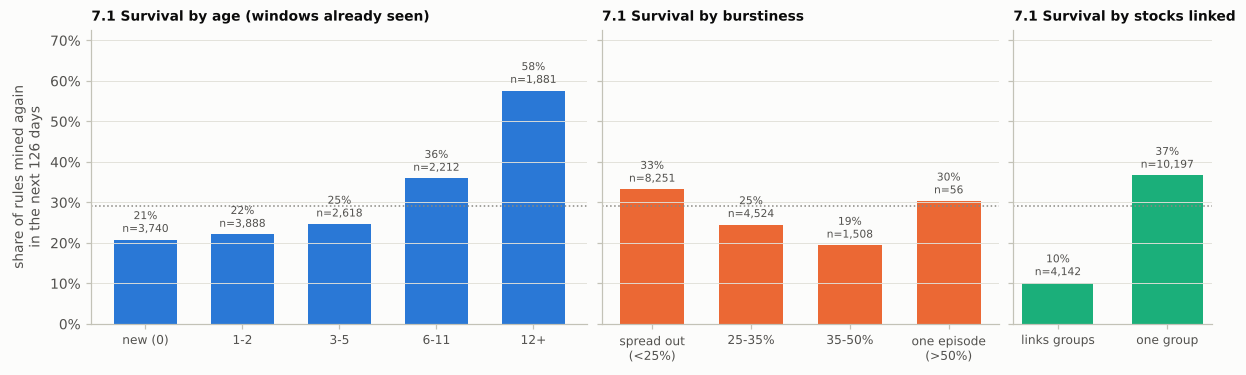

In [22]:
# 7.1 Descriptive view first: survival rate by age and by burstiness (all labelled rules).
def rate_by_bins(df, col, bins, labels):
    b = pd.cut(df[col], bins=bins, labels=labels, include_lowest=True)
    return df.groupby(b, observed=False)["survived"].agg(["mean", "size"])


by_age = rate_by_bins(labelled, "age", [-0.5, 0.5, 2.5, 5.5, 11.5, 1000], ["new (0)", "1-2", "3-5", "6-11", "12+"])
by_burst = rate_by_bins(labelled, "burstiness", [0, 0.25, 0.35, 0.5, 1.0], ["spread out\n(<25%)", "25-35%", "35-50%", "one episode\n(>50%)"])
by_kind = labelled.groupby(np.where(labelled["cross_group"] == 1, "links groups", "one group"))["survived"].agg(["mean", "size"])
KEY["survival_descriptive"] = {"by_age": by_age.round(3).to_dict(orient="index"), "by_burstiness": by_burst.round(3).to_dict(orient="index"),
                               "by_group_link": by_kind.round(3).to_dict(orient="index")}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), sharey=True, layout="constrained", gridspec_kw={"width_ratios": [5, 4, 2]})
for ax, table, title, c in [(axes[0], by_age, "by age (windows already seen)", "#2a78d6"),
                            (axes[1], by_burst, "by burstiness", "#eb6834"), (axes[2], by_kind, "by stocks linked", "#1baf7a")]:
    bars = ax.bar(range(len(table)), table["mean"], color=c, width=0.65)
    ax.set_xticks(range(len(table)), table.index, fontsize=8)
    for i, (m, n) in enumerate(zip(table["mean"], table["size"])):
        ax.text(i, m + 0.01, f"{m:.0%}\nn={n:,}", ha="center", va="bottom", fontsize=7, color=INK_SOFT)
    ax.axhline(labelled["survived"].mean(), color=MUTED, ls=":", lw=1)
    ax.set_title(f"7.1 Survival {title}", fontsize=9)
    ax.grid(axis="y")
axes[0].set_ylabel("share of rules mined again\nin the next 126 days")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].set_ylim(0, max(by_age["mean"].max(), by_burst["mean"].max()) + 0.15)
save(fig, "7_1_survival_by_feature")
plt.show()

In [23]:
# 7.2 Models against one-feature baselines, trained before ChatGPT and tested after it.
def precision_at(y, score, top=0.2):
    # Precision among the top 20% of rules by score: "if we only trusted these, how many would hold?"
    k = max(1, int(len(y) * top))
    return float(np.asarray(y)[np.argsort(-np.asarray(score))[:k]].mean())


def evaluate(y, score):
    return {"ROC-AUC": roc_auc_score(y, score), "PR-AUC": average_precision_score(y, score), "precision@20%": precision_at(y, score)}


MODELS = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)),
    "random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEED),
    "gradient boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=SEED),
}
results, fitted = {}, {}
for name, model in MODELS.items():
    model.fit(train[FEATURES], train["survived"])
    prob = model.predict_proba(test[FEATURES])[:, 1]
    fitted[name] = model
    results[name] = evaluate(test["survived"], prob) | {"Brier": brier_score_loss(test["survived"], prob)}
for col in ["lift", "support", "confidence", "age"]:
    results[f"baseline: rank by {col}"] = evaluate(test["survived"], test[col] + 1e-9 * test["support"])
results["baseline: all rules survive"] = {"ROC-AUC": 0.5, "PR-AUC": test["survived"].mean(), "precision@20%": test["survived"].mean()}
results = pd.DataFrame(results).T
results.to_csv(OUT_DIR / "survival_model_results.csv")
KEY["survival_models"] = results.round(3).to_dict(orient="index")
results.round(3)

,ROC-AUC,PR-AUC,precision@20%,Brier
logistic regression,0.646,0.580,0.644,0.218
random forest,0.658,0.584,0.623,0.208
gradient boosting,0.637,0.561,0.576,0.219
baseline: rank by lift,0.584,0.399,0.387,NaN
baseline: rank by support,0.610,0.493,0.523,NaN
baseline: rank by confidence,0.564,0.389,0.354,NaN
baseline: rank by age,0.627,0.570,0.618,NaN
baseline: all rules survive,0.500,0.357,0.357,NaN


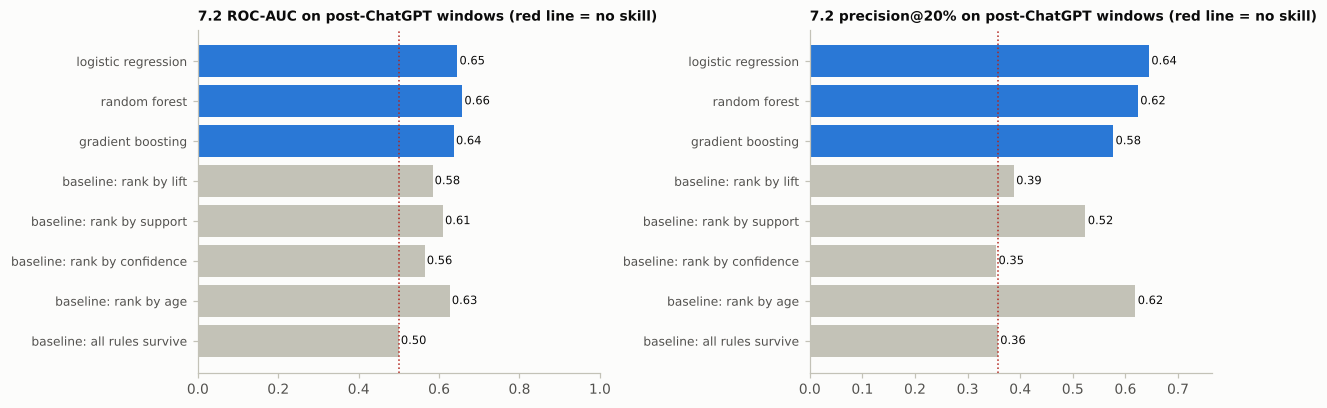

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
order = results.index.tolist()
colors_ = ["#2a78d6" if not n.startswith("baseline") else AXIS for n in order]
for ax, metric in zip(axes, ["ROC-AUC", "precision@20%"]):
    ax.barh(range(len(order))[::-1], results[metric], color=colors_)
    ax.set_yticks(range(len(order))[::-1], order, fontsize=8)
    for i, v in zip(range(len(order))[::-1], results[metric]):
        ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=7.5)
    ax.set_xlim(0, max(1, results[metric].max() + 0.1) if metric == "ROC-AUC" else results[metric].max() + 0.12)
    ref = 0.5 if metric == "ROC-AUC" else test["survived"].mean()
    ax.axvline(ref, color=HIGHLIGHT, ls=":", lw=1)
    ax.set_title(f"7.2 {metric} on post-ChatGPT windows (red line = no skill)", fontsize=9)
save(fig, "7_2_survival_models")
plt.show()

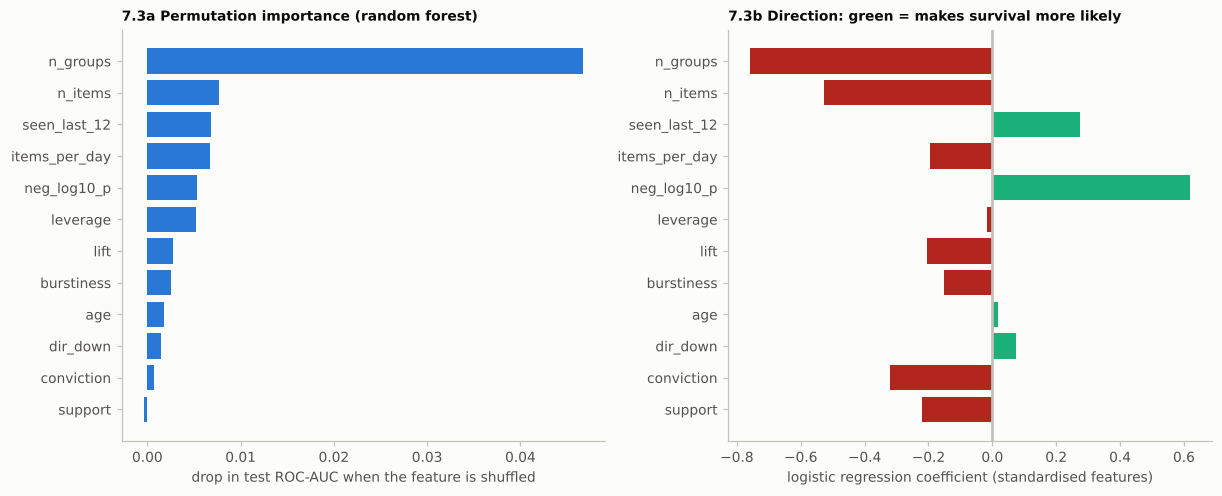

In [25]:
# 7.3 What makes a rule last? Permutation importance on the test set, plus the logistic regression's signs.
best_name = results.loc[list(MODELS), "ROC-AUC"].idxmax()
imp = permutation_importance(fitted[best_name], test[FEATURES], test["survived"], scoring="roc_auc",
                             n_repeats=10, random_state=SEED, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
coef = pd.Series(fitted["logistic regression"][-1].coef_[0], index=FEATURES)
KEY["survival_importance"] = {"model": best_name, "top": importance.sort_values(ascending=False).head(8).round(4).to_dict(),
                              "logit_coef": coef.round(3).to_dict()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
top_imp = importance.tail(12)
axes[0].barh(top_imp.index, top_imp.values, color="#2a78d6")
axes[0].set_xlabel("drop in test ROC-AUC when the feature is shuffled")
axes[0].set_title(f"7.3a Permutation importance ({best_name})", fontsize=9)
c_sorted = coef.reindex(top_imp.index)
axes[1].barh(c_sorted.index, c_sorted.values, color=[("#1baf7a" if v > 0 else "#b3261e") for v in c_sorted.values])
axes[1].axvline(0, color=AXIS)
axes[1].set_xlabel("logistic regression coefficient (standardised features)")
axes[1].set_title("7.3b Direction: green = makes survival more likely", fontsize=9)
save(fig, "7_3_survival_importance")
plt.show()

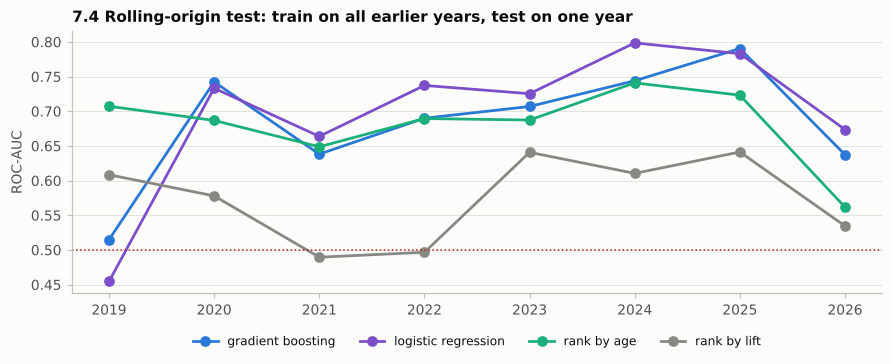

,test rules,survival rate,gradient boosting,logistic regression,rank by lift,rank by age
year,,,,,,
2019,1444,0.283,0.515,0.455,0.608,0.707
2020,1683,0.267,0.742,0.733,0.578,0.687
2021,2504,0.239,0.638,0.664,0.490,0.649
2022,2100,0.222,0.690,0.737,0.497,0.689
2023,985,0.299,0.707,0.725,0.641,0.687
2024,1293,0.303,0.744,0.799,0.610,0.741
2025,1177,0.329,0.790,0.783,0.641,0.723
2026,1582,0.482,0.637,0.674,0.535,0.562


In [26]:
# 7.4 Rolling-origin check: retrain each year on everything known before it, test on that year's windows.
roll = []
for year in range(2019, 2027):
    start_y = pd.Timestamp(f"{year}-01-01")
    tr = labelled[labelled["future_end"] < start_y]
    te = labelled[(labelled["window_end"] >= start_y) & (labelled["window_end"] < pd.Timestamp(f"{year + 1}-01-01"))]
    if len(te) < 50 or te["survived"].nunique() < 2:
        continue
    m = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=SEED).fit(tr[FEATURES], tr["survived"])
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(tr[FEATURES], tr["survived"])
    roll.append({"year": year, "test rules": len(te), "survival rate": te["survived"].mean(),
                 "gradient boosting": roc_auc_score(te["survived"], m.predict_proba(te[FEATURES])[:, 1]),
                 "logistic regression": roc_auc_score(te["survived"], lr.predict_proba(te[FEATURES])[:, 1]),
                 "rank by lift": roc_auc_score(te["survived"], te["lift"]),
                 "rank by age": roc_auc_score(te["survived"], te["age"] + 1e-9 * te["support"])})
roll = pd.DataFrame(roll).set_index("year")
roll.to_csv(OUT_DIR / "survival_rolling_origin.csv")
KEY["survival_rolling"] = roll.round(3).to_dict(orient="index")

fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
for col, c in zip(["gradient boosting", "logistic regression", "rank by age", "rank by lift"], ["#2a78d6", "#7a4fc9", "#1baf7a", MUTED]):
    ax.plot(roll.index, roll[col], marker="o", color=c, label=col)
ax.axhline(0.5, color=HIGHLIGHT, ls=":", lw=1)
ax.set_ylabel("ROC-AUC")
ax.set_xticks(roll.index)
ax.grid(axis="y")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("7.4 Rolling-origin test: train on all earlier years, test on one year")
save(fig, "7_4_survival_rolling_origin")
plt.show()
roll.round(3)

In [27]:
# 7.5 The actionable output: rules in the latest window, scored by the model trained on every labelled rule.
final_model = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=SEED)
final_model.fit(labelled[FEATURES], labelled["survived"])
latest = survival[survival["window_end"] == END_DATES[-1]].copy()
latest["p_survive"] = final_model.predict_proba(latest[FEATURES])[:, 1]
cols = ["rule", "lift", "confidence", "age", "burstiness", "p_survive"]
durable = latest.sort_values("p_survive", ascending=False)[cols].head(10)
fragile = latest[latest["lift"] >= latest["lift"].quantile(0.75)].sort_values("p_survive")[cols].head(10)
durable.to_csv(OUT_DIR / "latest_durable_rules.csv", index=False)
fragile.to_csv(OUT_DIR / "latest_fragile_rules.csv", index=False)
KEY["latest_rules"] = {"window_end": str(END_DATES[-1].date()), "n_rules": len(latest),
                       "durable": durable.round(3).to_dict(orient="records"), "fragile": fragile.round(3).to_dict(orient="records")}
print(f"Most durable rules in the window ending {END_DATES[-1].date()}:")
durable.round(2)

Most durable rules in the window ending 2026-11-13:


,rule,lift,confidence,age,burstiness,p_survive
23141,AMAT_DOWN -> LRCX_DOWN,5.21,0.76,113,0.19,1.00
23135,LRCX_DOWN -> AMAT_DOWN,5.21,0.70,113,0.19,1.00
23830,LRCX_UP -> AMAT_UP,4.15,0.71,112,0.21,1.00
23829,AMAT_UP -> LRCX_UP,4.15,0.79,102,0.21,1.00
23827,ASML_DOWN -> LRCX_DOWN,4.16,0.61,53,0.18,0.99
24074,ASML_UP -> AMAT_UP,3.77,0.64,46,0.19,0.97
23520,ACN_DOWN -> CTSH_DOWN,4.57,0.72,24,0.14,0.97
23521,CTSH_DOWN -> ACN_DOWN,4.57,0.72,24,0.14,0.97
22889,ACN_UP -> CTSH_UP,5.57,0.73,12,0.15,0.97
22890,CTSH_UP -> ACN_UP,5.57,0.82,12,0.15,0.97


In [28]:
print("Strong-looking rules (top 25% lift) the model expects to fade:")
fragile.round(2)

Strong-looking rules (top 25% lift) the model expects to fade:


,rule,lift,confidence,age,burstiness,p_survive
22777,"CAT_UP, MSFT_DOWN -> SAP_DOWN",5.82,0.79,5,0.27,0.00
22794,"MSFT_DOWN, SAP_DOWN -> CAT_UP",5.78,0.73,5,0.27,0.00
22491,"CAT_UP, SAP_DOWN -> MSFT_DOWN",7.22,0.92,5,0.27,0.00
22490,"AMAT_DOWN, NFLX_UP -> ADSK_UP",7.41,1.00,1,0.27,0.01
22685,"ADSK_UP, CAT_DOWN -> AMAT_DOWN",6.02,0.81,1,0.23,0.01
22617,"ADSK_UP, NFLX_UP -> AMAT_DOWN",6.27,0.85,1,0.27,0.01
22565,"ADSK_UP, AMAT_DOWN -> NFLX_UP",6.42,0.61,1,0.27,0.01
22566,"NFLX_UP -> ADSK_UP, AMAT_DOWN",6.42,0.46,1,0.27,0.01
22841,"CAT_DOWN -> ADSK_UP, AMAT_DOWN",5.69,0.41,1,0.23,0.01
22780,"LRCX_UP, MSFT_DOWN -> SAP_DOWN",5.82,0.79,1,0.27,0.01


## 8. Shock days: anomaly detection on daily baskets

Your earlier redesign idea was to study market events. Instead of tagging events by hand (which picks events *because* the market moved), we let an **Isolation Forest** find unusual days. It builds random trees that split the 40 residual z-scores at random; a day that can be separated from the rest in very few splits is unusual. We compare it with the simplest possible detector, the number of items in the basket, and then look up where known AI events land.

In [29]:
Z = zscores_by_mode[MAIN_MODE].clip(-10, 10).fillna(0)
forest = IsolationForest(n_estimators=300, contamination=0.01, random_state=SEED).fit(Z)
anomaly = pd.Series(-forest.score_samples(Z), index=Z.index, name="anomaly score")   # higher = more unusual
size = items.sum(axis=1)
top_if = set(anomaly.nlargest(int(0.01 * len(anomaly))).index)
top_size = set(size.nlargest(int(0.01 * len(size))).index)
agreement = len(top_if & top_size) / len(top_if | top_size)


def describe_day(day, n=6):
    z = Z.loc[day]
    movers = z.abs().sort_values(ascending=False).head(n).index
    return ", ".join(f"{t} {z[t]:+.1f}" for t in movers)


top_days = pd.DataFrame({"anomaly score": anomaly.nlargest(12).round(3),
                         "items in basket": size.loc[anomaly.nlargest(12).index],
                         "largest residual moves (z)": [describe_day(d) for d in anomaly.nlargest(12).index]})
events = []
for date, label in AI_EVENTS.items():
    d = pd.Timestamp(date)
    events.append({"date": date, "event": label, "anomaly percentile": float((anomaly <= anomaly.loc[d]).mean()),
                   "items in basket": int(size.loc[d]), "largest residual moves (z)": describe_day(d),
                   **{f"{SHORT[g]} net up": int(items.loc[d, [f"{t}_UP" for t in m]].sum() - items.loc[d, [f"{t}_DOWN" for t in m]].sum())
                      for g, m in GROUPS.items()}})
events = pd.DataFrame(events).set_index("date")
top_days.to_csv(OUT_DIR / "top_anomalous_days.csv")
events.to_csv(OUT_DIR / "ai_event_case_studies.csv")
KEY["anomaly"] = {"jaccard_if_vs_basket_size_top1pct": round(agreement, 3),
                  "top_days": {str(k.date()): v for k, v in top_days["largest residual moves (z)"].items()},
                  "events": events[["anomaly percentile", "items in basket", "largest residual moves (z)"]].round(3).to_dict(orient="index")}
print(f"Overlap of the top-1% days from Isolation Forest and from basket size (Jaccard): {agreement:.2f}")
top_days

Overlap of the top-1% days from Isolation Forest and from basket size (Jaccard): 0.50


,anomaly score,items in basket,largest residual moves (z)
Date,,,
2017-06-09,0.599,29,"PFE +6.7, CRM -6.0, AMAT -5.5, META -5.1, AAPL..."
2016-11-10,0.595,33,"GOOGL -5.6, JPM +5.5, KO -5.5, IBM +4.8, PG -4..."
2020-03-18,0.584,33,"ASML -8.3, CSCO +7.0, AVGO -5.8, LRCX -4.4, CH..."
2017-11-29,0.580,31,"ADSK -10.0, LRCX -5.9, AMAT -5.3, ASML -5.3, W..."
2016-11-09,0.575,34,"PFE +10.0, CAT +6.9, JPM +4.5, CHGG +4.1, TSM ..."
2020-11-09,0.564,23,"PG -7.4, JPM +6.8, HD -6.7, PFE +5.8, XOM +5.6..."
2020-03-13,0.563,28,"ORCL +9.8, ADBE +9.0, JPM +6.4, INTC +6.0, XOM..."
2024-11-06,0.558,24,"JPM +8.2, HD -5.6, SAP -5.2, CAT +4.6, CTSH +4..."
2020-03-23,0.557,29,"HD +5.9, NFLX +5.4, AMAT +5.4, ADBE +5.4, SAP ..."


In [30]:
events

,event,anomaly percentile,items in basket,largest residual moves (z),AI net up,BigTech net up,Software net up,Baseline net up
date,,,,,,,,
2022-11-30,"ChatGPT released (same day: Powell speech, S&P...",0.683864,13,"WDAY +5.8, MSFT +1.8, QCOM +1.7, AVGO +1.5, UN...",2,3,2,0
2023-03-14,GPT-4 announced,0.485181,10,"ORCL -1.9, HD -1.6, IBM -1.6, META +1.4, AMD +...",2,-1,-2,-1
2023-05-25,Nvidia's AI revenue guidance,0.993414,24,"NVDA +10.0, TSM +7.6, AVGO +5.6, ORCL +5.6, AD...",7,0,0,-7
2025-01-27,DeepSeek sell-off,0.996341,29,"CSCO -6.4, ORCL -6.4, NVDA -6.2, TSM -4.6, JNJ...",-6,1,6,8
2025-09-10,Oracle's $455bn cloud backlog,0.970362,18,"ORCL +10.0, AVGO +4.8, SAP -3.1, AAPL -2.9, CR...",4,-3,-6,-1


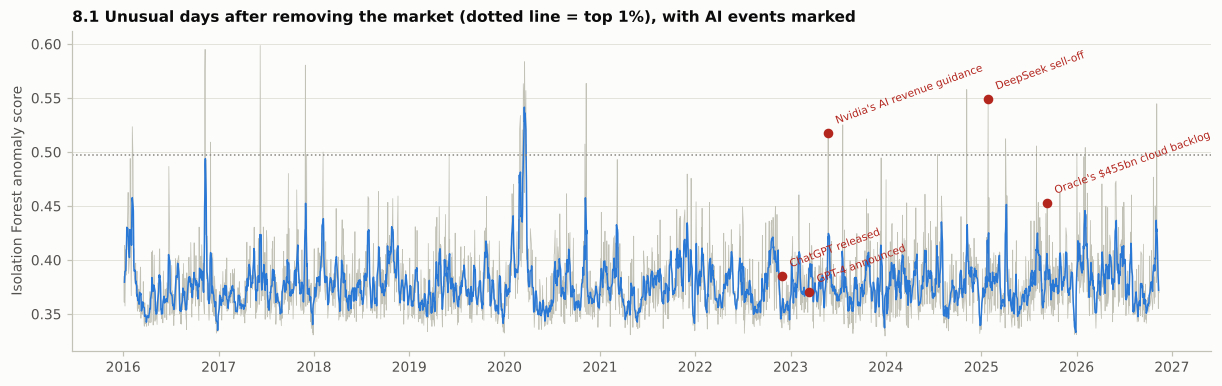

In [31]:
fig, ax = plt.subplots(figsize=(11, 3.4), layout="constrained")
smooth = anomaly.rolling(5, center=True).mean()
ax.plot(anomaly.index, anomaly, color=AXIS, lw=0.5)
ax.plot(smooth.index, smooth, color=MODE_COLORS["residual"], lw=1)
cut = anomaly.quantile(0.99)
ax.axhline(cut, color=MUTED, ls=":", lw=1)
for date, label in AI_EVENTS.items():
    d = pd.Timestamp(date)
    ax.scatter([d], [anomaly.loc[d]], color=HIGHLIGHT, s=28, zorder=5)
    ax.annotate(label.split(" (")[0], (d, anomaly.loc[d]), xytext=(4, 6), textcoords="offset points", fontsize=7, color=HIGHLIGHT, rotation=20)
ax.set_ylabel("Isolation Forest anomaly score")
ax.grid(axis="y")
year_axis(ax)
ax.set_title("8.1 Unusual days after removing the market (dotted line = top 1%), with AI events marked")
save(fig, "8_1_anomaly_timeline")
plt.show()

## 9. Summary of results

The cell below prints the numbers used in the slides and the report and writes them to `outputs/final/key_numbers.json`, so the documents and the code always agree. Interpretation is in the report; the main points are:

1. **Market removal (Section 4).** How much of the raw-return rule set is just the market.
2. **ChatGPT (Section 5).** Where the ChatGPT date ranks among placebo dates, and whether that survives other settings.
3. **The market's AI category (Section 6).** Which stocks joined or left the AI cluster beyond noise.
4. **Durability (Section 7).** Whether a rule's history predicts its future better than its strength, and what makes rules last.
5. **Shock days (Section 8).** Whether AI events stand out once the market is removed.

In [32]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, pd.Timestamp):
        return str(o.date())
    return o


KEY["settings"] = {"MAIN_MODE": MAIN_MODE, "Z_K": Z_K, "VOL_WINDOW": VOL_WINDOW, "BETA_WINDOW": BETA_WINDOW, "WINDOW": WINDOW,
                   "STEP": STEP, "MIN_SUPPORT": MIN_SUPPORT, "MIN_CONFIDENCE": MIN_CONFIDENCE, "MIN_LIFT": MIN_LIFT,
                   "MAX_LEN": MAX_LEN, "FUTURE_DAYS": FUTURE_DAYS, "CHATGPT_DATE": CHATGPT_DATE, "SEED": SEED}
with open(OUT_DIR / "key_numbers.json", "w") as f:
    json.dump(to_jsonable(KEY), f, indent=1)
print(json.dumps(to_jsonable({k: KEY[k] for k in ["rolling", "chance", "placebo", "survival_data"]}), indent=1))

{
 "rolling": {
  "n_windows": 120,
  "rules_median": {
   "excess": 277.0,
   "raw": 3905.0,
   "residual": 118.0
  },
  "rules_max": {
   "excess": 3050,
   "raw": 51138,
   "residual": 2097
  },
  "spearman_rules_vs_spy_vol": {
   "excess": 0.28,
   "raw": 0.71,
   "residual": 0.37
  }
 },
 "chance": {
  "n_possible_rules": 480480,
  "real_rules_total": 24585,
  "shuffled_rules_total": 67.0,
  "chance_ratio_overall": 0.003,
  "significant_share": 0.823
 },
 "placebo": {
  "n_candidate_dates": 107,
  "first": "2017-01-03",
  "last": "2025-11-03",
  "chatgpt_values": {
   "rule_turnover": 0.887,
   "tech_change_minus_control": 0.012,
   "ai_within_did": -0.207,
   "ai_software_change": 0.103
  },
  "chatgpt_percentile": {
   "rule_turnover": 0.62,
   "tech_change_minus_control": 0.29,
   "ai_within_did": 0.36,
   "ai_software_change": 0.21
  },
  "top_dates_tech_change": [
   "2025-11-03",
   "2025-10-01",
   "2025-09-02",
   "2025-08-01",
   "2024-08-01"
  ],
  "top_dates_turnover": 